# Only Eyetracking data
This just uses fixation duration. Maybe add Saccade features.

In [1]:
# Imports and config
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    make_scorer, f1_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix
)
import warnings
warnings.filterwarnings('ignore')

import sys
sys.path.append("..")
from data.data_loader import DataLoader
from data.data_configs import SUBJECTS, ALL_SUBJECTS

In [2]:
X_out, y_out, feature_names, subject_ids = DataLoader.load_et_features(SUBJECTS)

In [3]:
X_out.shape, y_out.shape

((61822, 33), (61822,))

In [4]:
print(f"Class distribution: {np.bincount(y_out.astype(int))}")

Class distribution: [26810 35012]


In [5]:
# %% Clean data - handle NaNs
df = pd.DataFrame(X_out, columns=feature_names)
nan_counts = df.isna().sum()
print(f"\nFeatures with NaNs: {(nan_counts > 0).sum()}")

# Remove features with >50% NaN
high_nan = nan_counts[nan_counts > len(df) * 0.5].index.tolist()
feature_names_clean = [f for f in feature_names if f not in high_nan]
print(f"Features after cleaning: {len(feature_names_clean)}")

# Impute remaining NaNs
X_clean = df[feature_names_clean].values
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_clean)


Features with NaNs: 21
Features after cleaning: 33


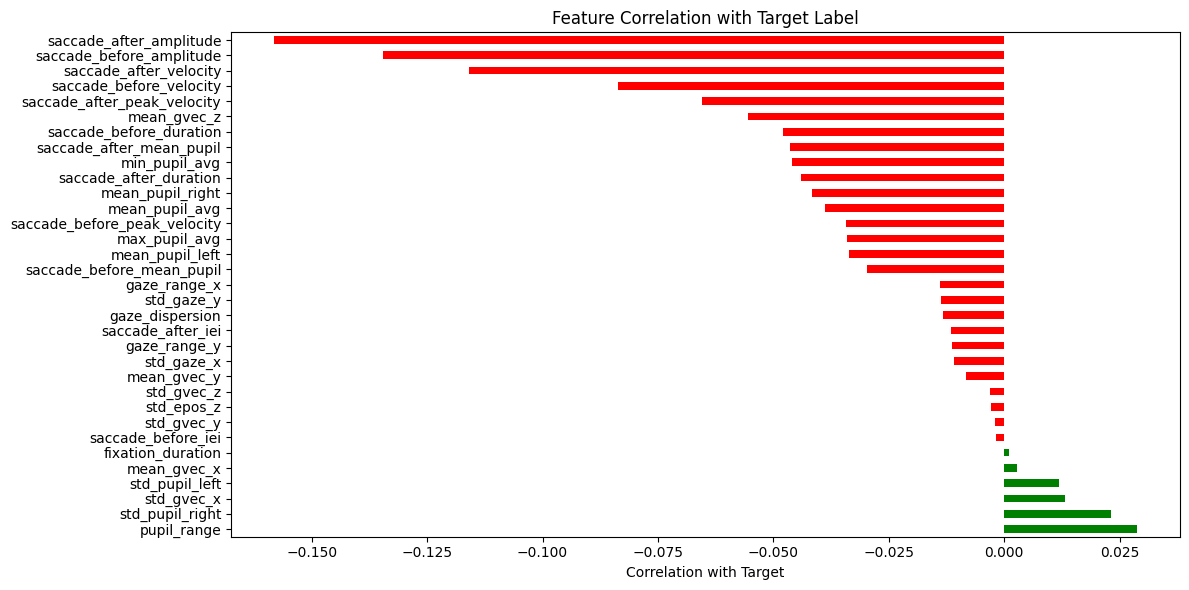


Top 5 correlated features:
pupil_range        0.028723
std_pupil_right    0.023185
std_gvec_x         0.013139
std_pupil_left     0.011925
mean_gvec_x        0.002675
Name: label, dtype: float64


In [6]:
# %% Correlation with label
temp_df = pd.DataFrame(X_imputed, columns=feature_names_clean)
temp_df['label'] = y_out
label_corr = temp_df.corr()['label'].drop('label').sort_values(ascending=False)

plt.figure(figsize=(12, 6))
label_corr.plot(kind='barh', color=['green' if x > 0 else 'red' for x in label_corr])
plt.xlabel('Correlation with Target')
plt.title('Feature Correlation with Target Label')
plt.tight_layout()
plt.show()

print(f"\nTop 5 correlated features:\n{label_corr.head()}")

In [7]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

In [8]:
# -------------------------
# Model
# -------------------------
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# -------------------------
# Scorers
# -------------------------
f1_macro_scorer = make_scorer(f1_score, average='macro')
balanced_acc_scorer = make_scorer(balanced_accuracy_score)




=== Stratified K-Fold CV ===


Fold 1: Accuracy=0.6638, Macro-F1=0.6439, Balanced Acc=0.6438
Fold 2: Accuracy=0.6577, Macro-F1=0.6379, Balanced Acc=0.6379
Fold 3: Accuracy=0.6650, Macro-F1=0.6435, Balanced Acc=0.6437
Fold 4: Accuracy=0.6601, Macro-F1=0.6405, Balanced Acc=0.6404
Fold 5: Accuracy=0.6622, Macro-F1=0.6417, Balanced Acc=0.6418

Overall Macro-F1: 0.6415
Overall Balanced Accuracy: 0.6415


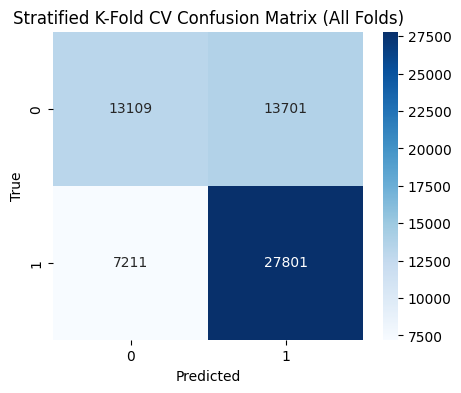

In [9]:
from sklearn.metrics import accuracy_score

# -------------------------
# 1. Stratified K-Fold CV with per-fold accuracy
# -------------------------
print("=== Stratified K-Fold CV ===")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_true_all, y_pred_all = [], []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_scaled, y_out), 1):
    model.fit(X_scaled[train_idx], y_out[train_idx])
    y_pred = model.predict(X_scaled[test_idx])
    
    # Store for overall metrics
    y_true_all.append(y_out[test_idx])
    y_pred_all.append(y_pred)
    
    # Compute fold metrics
    acc = accuracy_score(y_out[test_idx], y_pred)
    f1 = f1_score(y_out[test_idx], y_pred, average='macro')
    bal_acc = balanced_accuracy_score(y_out[test_idx], y_pred)
    print(f"Fold {fold}: Accuracy={acc:.4f}, Macro-F1={f1:.4f}, Balanced Acc={bal_acc:.4f}")

# Aggregate over all folds
y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)

f1_macro = f1_score(y_true_all, y_pred_all, average='macro')
bal_acc = balanced_accuracy_score(y_true_all, y_pred_all)
print(f"\nOverall Macro-F1: {f1_macro:.4f}")
print(f"Overall Balanced Accuracy: {bal_acc:.4f}")

# Confusion Matrix for all folds combined
cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Stratified K-Fold CV Confusion Matrix (All Folds)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


=== Grouped K-Fold CV (Subject-Level, 5 Splits) ===
Fold 1 | Subjects: ['P09' 'P21'] | Accuracy=0.6098, Macro-F1=0.5817, Balanced Acc=0.5871
Fold 2 | Subjects: ['P01' 'P17'] | Accuracy=0.6357, Macro-F1=0.6177, Balanced Acc=0.6168
Fold 3 | Subjects: ['P07' 'P16' 'P30'] | Accuracy=0.6052, Macro-F1=0.5897, Balanced Acc=0.5970
Fold 4 | Subjects: ['P20' 'P27' 'P38'] | Accuracy=0.5849, Macro-F1=0.5743, Balanced Acc=0.5773
Fold 5 | Subjects: ['P10' 'P28' 'P34'] | Accuracy=0.6247, Macro-F1=0.6193, Balanced Acc=0.6204

Overall Macro-F1: 0.5971
Overall Balanced Accuracy: 0.5968


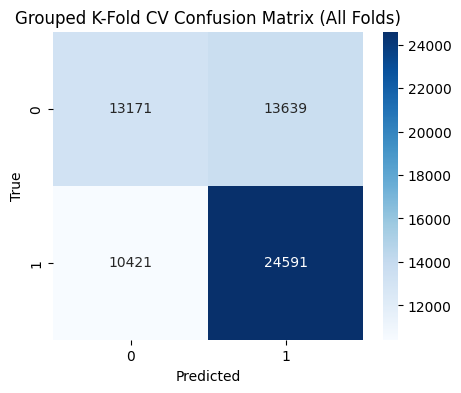

In [10]:
# Make sure subject_ids is a NumPy array
subject_ids = np.array(subject_ids)

print("=== Grouped K-Fold CV (Subject-Level, 5 Splits) ===")
gkf = GroupKFold(n_splits=5)
y_true_all, y_pred_all = [], []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_scaled, y_out, groups=subject_ids), 1):
    model.fit(X_scaled[train_idx], y_out[train_idx])
    y_pred = model.predict(X_scaled[test_idx])
    
    # Store for overall metrics
    y_true_all.append(y_out[test_idx])
    y_pred_all.append(y_pred)
    
    # Fold-level metrics
    acc = accuracy_score(y_out[test_idx], y_pred)
    f1 = f1_score(y_out[test_idx], y_pred, average='macro')
    bal_acc = balanced_accuracy_score(y_out[test_idx], y_pred)
    subjects_in_fold = np.unique(subject_ids[test_idx])
    print(f"Fold {fold} | Subjects: {subjects_in_fold} | Accuracy={acc:.4f}, Macro-F1={f1:.4f}, Balanced Acc={bal_acc:.4f}")

# Aggregate over all folds
y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)

print(f"\nOverall Macro-F1: {f1_score(y_true_all, y_pred_all, average='macro'):.4f}")
print(f"Overall Balanced Accuracy: {balanced_accuracy_score(y_true_all, y_pred_all):.4f}")

# Confusion Matrix for all folds combined
cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Grouped K-Fold CV Confusion Matrix (All Folds)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
